# AnaeCare — Quick Fusion Test (Concat vs Self-Attention), 20 Epochs

**Kaggle version — GPU T4 x2.** Adapted for Kaggle Notebooks: no Google Drive
mount, dataset paths are auto-detected under `/kaggle/input/` (matching the
4 attached datasets — `Dataset2`, `palmas_processed`, `unas_processed`,
`yemas_frames`), results are written to `/kaggle/working/` (the only writable
area on Kaggle — `/kaggle/input/` is read-only), and training uses both T4s
via `nn.DataParallel` automatically when 2 GPUs are visible.

**Before running:** in the notebook's right-hand panel, set **Accelerator ->
GPU T4 x2**, and make sure all 4 datasets shown in your **Input** panel
(`Dataset2`, `palmas_processed`, `unas_processed`, `yemas_frames`) are
attached — that's it, no path editing needed unless your dataset names
differ from those.

**No OpenCV video decoding happens anymore.** `yemas`/`palmas` frames are read
directly as images and evenly sampled (32 for YEMAS, 16 for PALMAS) from
whatever's already in each subject's frame folder.

Every step is numbered — run top to bottom.


## Step 1 — Imports & GPU Setup

No Drive mount needed on Kaggle — inputs are already mounted at `/kaggle/input/`.


In [12]:
import os
import json
import random
from datetime import datetime

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

random.seed(42); np.random.seed(42); torch.manual_seed(42)

# --- GPU setup (Kaggle "GPU T4 x2" = two physical T4s visible to this container) ---
N_GPUS = torch.cuda.device_count() if torch.cuda.is_available() else 0
DEVICE = torch.device("cuda" if N_GPUS > 0 else "cpu")
USE_MULTI_GPU = N_GPUS > 1   # quick_run() wraps the model in nn.DataParallel when True

print("Using device:", DEVICE)
if N_GPUS > 0:
    for i in range(N_GPUS):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")
print(f"USE_MULTI_GPU = {USE_MULTI_GPU}  ({N_GPUS} GPU(s) visible)")
if N_GPUS == 0:
    print("WARNING: no GPU visible - set Accelerator -> GPU T4 x2 in the notebook settings panel and restart.")


Using device: cuda
  GPU 0: Tesla T4
  GPU 1: Tesla T4
USE_MULTI_GPU = True  (2 GPU(s) visible)


## Step 1.5 — See What Kaggle Actually Mounted (run this first)

Prints the real folder tree under `/kaggle/input` up to 3 levels deep. Copy
the exact paths you see here into the manual override section in Step 2 —
this sidesteps auto-detection entirely, so there's no more guessing.


In [13]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.count(os.sep) - "/kaggle/input".count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    indent = "  " * depth
    print(f"{indent}{os.path.basename(root) or root}/")
    for fn in sorted(files):
        print(f"{indent}  {fn}")


input/
  datasets/
    shimu080/
      unas-palmas-yemas/
      dataset2/
        Dataset2.csv
      metadata/
        metadata.csv


## Step 2 — Config: Paths & Settings (manual paths, with auto-detect fallback)

**Fill in `MANUAL_PATHS` below using what Step 1.5 printed** — that's the
real, verified folder tree, so there's no guessing involved. Paste each path
in as a plain string (right up to the folder that directly contains the
`Leve` / `Moderada` / `Normal` class folders, or the CSV file itself for
`csv`). Leave any entry as `None` to fall back to auto-detection for just
that one item — but manual is the reliable option, use it if auto-detect has
failed before.

`RESULTS_DIR` lives under `/kaggle/working/` — the only writable location on
Kaggle (`/kaggle/input/` is strictly read-only).


In [14]:
# --- Manual path overrides ---
# Copy the exact paths from the Step 1.5 output above. Example, if Step 1.5 printed:
#   yemas_frames/
#     yemas_frames/
#       Leve/
#       Moderada/
#       Normal/
# then the path you want is "/kaggle/input/yemas_frames/yemas_frames" (the
# folder that directly CONTAINS Leve/Moderada/Normal, not the folder above it).
MANUAL_PATHS = {
    "csv":    "/kaggle/input/datasets/shimu080/dataset2/Dataset2.csv",                     # <-- EDIT: exact path to Dataset2.csv
    "yemas":  "/kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames",                 # <-- EDIT
    "palmas": "/kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames",            # <-- EDIT
    "unas":   "/kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images",             # <-- EDIT
}

KAGGLE_INPUT_ROOT = "/kaggle/input"
RESULTS_DIR_ROOT = "/kaggle/working"
_available_inputs = sorted(os.listdir(KAGGLE_INPUT_ROOT)) if os.path.isdir(KAGGLE_INPUT_ROOT) else []

def find_input_dataset(*keywords):
    """Auto-detect fallback: first folder directly under /kaggle/input whose
    name contains any of the given keywords. Only used when the matching
    MANUAL_PATHS entry above is None."""
    for entry in _available_inputs:
        full = os.path.join(KAGGLE_INPUT_ROOT, entry)
        if os.path.isdir(full) and any(k in entry.lower() for k in keywords):
            return full
    return None

def descend_if_nested(base, *keywords):
    if base is None or not os.path.isdir(base):
        return base
    for child in sorted(os.listdir(base)):
        child_path = os.path.join(base, child)
        if os.path.isdir(child_path) and any(k in child.lower() for k in keywords):
            if any(os.path.isdir(os.path.join(child_path, g)) for g in os.listdir(child_path)):
                return child_path
    return base

def find_csv_in(base):
    if base is None or not os.path.isdir(base):
        return None
    for f in sorted(os.listdir(base)):
        if f.lower().endswith(".csv"):
            return os.path.join(base, f)
    return None

# Manual path wins if set; otherwise fall back to auto-detection.
SPLIT_CSV_PATH = MANUAL_PATHS["csv"] or find_csv_in(find_input_dataset("dataset2", "dataset"))
YEMAS_DIR  = MANUAL_PATHS["yemas"]  or descend_if_nested(find_input_dataset("yemas"), "yemas")
PALMAS_DIR = MANUAL_PATHS["palmas"] or descend_if_nested(find_input_dataset("palmas", "palma"), "palmas", "palma")
UNAS_DIR   = MANUAL_PATHS["unas"]   or descend_if_nested(find_input_dataset("unas"), "unas")
FALLBACK_METADATA_CSV = SPLIT_CSV_PATH  # same source on Kaggle, kept for Step 4 compatibility

# Dedicated results folder in the writable Kaggle output area.
STAMP_RESULTS_BY_DATE = True
_run_date = datetime.now().strftime("%Y-%m-%d")
RESULTS_DIR = os.path.join(RESULTS_DIR_ROOT, "AnaeCare_results", "quick_fusion_test")
if STAMP_RESULTS_BY_DATE:
    RESULTS_DIR = os.path.join(RESULTS_DIR, _run_date)
os.makedirs(RESULTS_DIR, exist_ok=True)

EXPECTED_FRAME_COUNTS = {"yemas": 32, "palmas": 16}  # frames SAMPLED from each subject's extracted-frame folder
FRAME_IMAGE_EXTS = (".jpg", ".jpeg", ".png")          # extracted yemas/palmas frame files
IMAGE_EXTS = (".jpg", ".jpeg", ".png")                # single cropped unas nail image

# Folder-name template for each subject's extracted frames, relative to
# <modality_dir>/<Class>/ . Default assumes .../yemas_frames/<Class>/<ID>/frame_0001.jpg etc.
# Edit if your frames sit in a differently-named subfolder, e.g. "{id}_frames".
FRAME_FOLDER_TEMPLATE = "{id}"

# --- Run settings ---
SUBSET_SIZE = None     # None = use the full split file; set a number for a faster partial run
QUICK_EPOCHS = 20
BATCH_SIZE = 16 if USE_MULTI_GPU else 8   # bumped for 2x T4 so both GPUs stay fed
TEMPORAL_POOLING = "mean"   # "mean" or "bilstm"

print("SPLIT_CSV_PATH:", SPLIT_CSV_PATH or "NOT FOUND")
print("YEMAS_DIR     :", YEMAS_DIR or "NOT FOUND")
print("PALMAS_DIR    :", PALMAS_DIR or "NOT FOUND")
print("UNAS_DIR      :", UNAS_DIR or "NOT FOUND")
print("RESULTS_DIR   :", RESULTS_DIR, "(writable Kaggle output area)")
print(f"SUBSET_SIZE={SUBSET_SIZE}  QUICK_EPOCHS={QUICK_EPOCHS}  BATCH_SIZE={BATCH_SIZE}  TEMPORAL_POOLING={TEMPORAL_POOLING}")
if not (SPLIT_CSV_PATH and YEMAS_DIR and PALMAS_DIR and UNAS_DIR):
    print("\nSome paths above are NOT FOUND. Check the MANUAL_PATHS dict against the "
          "Step 1.5 output and fix the ones that don't match.")


SPLIT_CSV_PATH: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
YEMAS_DIR     : /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
PALMAS_DIR    : /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
UNAS_DIR      : /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
RESULTS_DIR   : /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22 (writable Kaggle output area)
SUBSET_SIZE=None  QUICK_EPOCHS=20  BATCH_SIZE=16  TEMPORAL_POOLING=mean


## Step 3 — Verify Resolved Dataset Paths

Asserts each path from Step 2 (manual or auto-detected) was actually found
and prints the class folders inside it, so a bad path is obvious immediately
instead of after a long training run.


In [15]:
for label, d in [("YEMAS", YEMAS_DIR), ("PALMAS", PALMAS_DIR), ("UNAS", UNAS_DIR)]:
    assert d is not None and os.path.isdir(d), (
        f"{label}_DIR not found at: {d}\n"
        f"Fix MANUAL_PATHS['{label.lower()}'] in Step 2 - copy the exact path from the "
        f"Step 1.5 listing above (the folder that directly contains Leve/Moderada/Normal)."
    )
    classes = [c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c))]
    print(f"{label}_DIR -> {d}")
    print(f"  class folders found = {classes}")

assert SPLIT_CSV_PATH is not None and os.path.isfile(SPLIT_CSV_PATH), (
    f"Split CSV not found at: {SPLIT_CSV_PATH}\n"
    f"Fix MANUAL_PATHS['csv'] in Step 2 - copy the exact path to Dataset2.csv from the "
    f"Step 1.5 listing above."
)
print("\nSPLIT_CSV_PATH ->", SPLIT_CSV_PATH)


YEMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/yemas_frames/yemas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
PALMAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/palmas_frames/palmas_frames
  class folders found = ['Leve', 'Moderada', 'Normal']
UNAS_DIR -> /kaggle/input/datasets/shimu080/unas-palmas-yemas/unas_images/unas_images
  class folders found = ['Leve', 'Moderada', 'Normal']

SPLIT_CSV_PATH -> /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv


## Step 4 — Load Your Split File

Drops blank filler rows, keeps `ID` / `Class` / `Anemia Predict` / `Split`.
Falls back to `dataset/metadata.csv` if `SPLIT_CSV_PATH` isn't found (note: the
fallback file may not have a `Split` column - handled below).

In [16]:
if os.path.isfile(SPLIT_CSV_PATH):
    metadata_source = SPLIT_CSV_PATH
elif os.path.isfile(FALLBACK_METADATA_CSV):
    metadata_source = FALLBACK_METADATA_CSV
    print(f"SPLIT_CSV_PATH not found - falling back to {FALLBACK_METADATA_CSV}")
else:
    raise FileNotFoundError(
        f"Could not find a metadata/split file at either:\n  {SPLIT_CSV_PATH}\n  {FALLBACK_METADATA_CSV}\n"
        f"Attach the dataset containing your split CSV as a Kaggle Input, or fix SPLIT_CSV_PATH in Step 2."
    )

print("Using metadata file:", metadata_source)
raw_df = pd.read_csv(metadata_source)
metadata_df = raw_df.dropna(subset=["ID"]).copy()

required_cols = ["ID", "Class", "Anemia Predict"]
missing_cols = [c for c in required_cols if c not in metadata_df.columns]
assert not missing_cols, f"Metadata file is missing required columns: {missing_cols}"
has_split_col = "Split" in metadata_df.columns

keep_cols = required_cols + (["Split"] if has_split_col else [])
metadata_df = metadata_df[keep_cols].reset_index(drop=True)
metadata_df["ID"] = metadata_df["ID"].astype(str).str.strip()
metadata_df["Class"] = metadata_df["Class"].astype(str).str.strip()
if has_split_col:
    metadata_df["Split"] = metadata_df["Split"].astype(str).str.strip()
else:
    print("WARNING: no 'Split' column in this metadata file - a fresh stratified 70/15/15 "
          "split will be created for you in Step 5 instead of using a provided one.")

print(f"{len(metadata_df)} subjects in metadata.")
if has_split_col:
    print(metadata_df["Split"].value_counts())

Using metadata file: /kaggle/input/datasets/shimu080/dataset2/Dataset2.csv
909 subjects in metadata.
Split
train         636
validation    137
test          136
Name: count, dtype: int64


## Step 5 — Existence Check + Build Train / Val / Test

Checks each subject actually has extracted-frame files for `yemas`/`palmas`
(`dataset/<modality>/<Class>/<ID>/*.jpg`) and a cropped image for `unas`
(`dataset/unas/<Class>/<ID>.jpg`), then either uses your provided `Split`
column or creates a fresh stratified split if none was found.

In [17]:
def subject_frame_folder(modality_dir, subj_class, subj_id):
    """Path to a subject's extracted-frame folder, e.g. dataset/yemas/<Class>/<ID>/."""
    folder_name = FRAME_FOLDER_TEMPLATE.format(id=subj_id)
    return os.path.join(modality_dir, subj_class, folder_name)

def list_frame_files(folder):
    """All extracted frame image paths in a subject's folder, sorted by filename."""
    if not os.path.isdir(folder):
        return []
    files = sorted(f for f in os.listdir(folder) if f.lower().endswith(FRAME_IMAGE_EXTS))
    return [os.path.join(folder, f) for f in files]

def find_subject_file(modality_dir, subj_class, subj_id, exts):
    for ext in exts:
        p = os.path.join(modality_dir, subj_class, subj_id + ext)
        if os.path.isfile(p):
            return p
    return None

def subject_exists(subj_id, subj_class):
    y = len(list_frame_files(subject_frame_folder(YEMAS_DIR, subj_class, subj_id))) > 0
    p = len(list_frame_files(subject_frame_folder(PALMAS_DIR, subj_class, subj_id))) > 0
    u = find_subject_file(UNAS_DIR, subj_class, subj_id, IMAGE_EXTS) is not None
    return y and p and u

tqdm.pandas(desc="Checking files exist")
metadata_df["exists_all_3"] = metadata_df.progress_apply(
    lambda r: subject_exists(r["ID"], r["Class"]), axis=1
)
usable_df = metadata_df[metadata_df["exists_all_3"]].reset_index(drop=True)
print(f"\n{len(usable_df)} / {len(metadata_df)} subjects have all 3 modality inputs on disk.")

if len(usable_df) == 0:
    sample_row = metadata_df.iloc[0]
    example_path = subject_frame_folder(YEMAS_DIR, sample_row["Class"], sample_row["ID"])
    raise RuntimeError(
        f"No subjects passed the existence check. Example frame folder tried:\n  {example_path}\n"
        f"Check DATASET_DIR / folder names in Steps 2-3, and confirm your extracted frames sit at "
        f"dataset/<modality>/<Class>/<ID>/*.jpg (edit FRAME_FOLDER_TEMPLATE in Step 2 if your subfolder "
        f"naming differs). Class folders found there were printed above, compare against Class values in "
        f"your metadata (e.g. '{sample_row['Class']}')."
    )

if SUBSET_SIZE is not None and len(usable_df) > SUBSET_SIZE:
    from sklearn.model_selection import train_test_split as _tts
    usable_df, _ = _tts(usable_df, train_size=SUBSET_SIZE, stratify=usable_df["Anemia Predict"], random_state=42)
    usable_df = usable_df.reset_index(drop=True)
    print(f"Subsampled down to {len(usable_df)} subjects (SUBSET_SIZE set).")

if has_split_col:
    train_df = usable_df[usable_df["Split"] == "train"].reset_index(drop=True)
    val_df   = usable_df[usable_df["Split"] == "validation"].reset_index(drop=True)
    test_df  = usable_df[usable_df["Split"] == "test"].reset_index(drop=True)
else:
    from sklearn.model_selection import train_test_split as _tts
    train_val_df, test_df = _tts(usable_df, test_size=0.15, stratify=usable_df["Anemia Predict"], random_state=42)
    train_df, val_df = _tts(train_val_df, test_size=0.15/0.85, stratify=train_val_df["Anemia Predict"], random_state=42)
    train_df, val_df, test_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

train_ids, val_ids, test_ids = set(train_df["ID"]), set(val_df["ID"]), set(test_df["ID"])
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
print("PASS: train/val/test are patient-level disjoint.")

print(f"\ntrain={len(train_df)}  val={len(val_df)}  test={len(test_df)}")
print("train class balance:", train_df["Anemia Predict"].value_counts().to_dict())
print("val class balance:  ", val_df["Anemia Predict"].value_counts().to_dict())
print("test class balance: ", test_df["Anemia Predict"].value_counts().to_dict())

Checking files exist:   0%|          | 0/909 [00:00<?, ?it/s]


737 / 909 subjects have all 3 modality inputs on disk.
PASS: train/val/test are patient-level disjoint.

train=512  val=115  test=110
train class balance: {0: 356, 1: 156}
val class balance:   {0: 81, 1: 34}
test class balance:  {0: 79, 1: 31}


## Step 6 — Frame Sampling (Pre-Extracted) + Dataset Class

`sample_frame_paths` evenly picks `n_frames` image paths (32 for YEMAS, 16 for
PALMAS) out of whatever's already in each subject's extracted-frame folder —
no video decoding. `TriModalDataset` uses this for the two video-derived
modalities and loads the UNAS `.jpg` directly, same as before.

In [18]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
frame_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

def sample_frame_paths(all_paths, n_frames):
    """Evenly sample n_frames image paths from an already-extracted frame
    folder. If fewer frames exist than n_frames, all are used (the caller
    pads the rest by repeating the last frame)."""
    if len(all_paths) == 0:
        return []
    if len(all_paths) <= n_frames:
        return all_paths
    indices = np.linspace(0, len(all_paths) - 1, n_frames).astype(int)
    return [all_paths[i] for i in indices]


class TriModalDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def _load_frame_sequence(self, modality_dir, subj_class, subj_id, n_frames):
        folder = subject_frame_folder(modality_dir, subj_class, subj_id)
        all_paths = list_frame_files(folder)
        chosen = sample_frame_paths(all_paths, n_frames)
        imgs = [self.transform(Image.open(p).convert("RGB")) for p in chosen]
        while len(imgs) < n_frames:  # defensive pad, e.g. a subject with fewer frames than expected
            imgs.append(imgs[-1].clone() if imgs else torch.zeros(3, 224, 224))
        return torch.stack(imgs)

    def _load_image(self, modality_dir, subj_class, subj_id):
        img_path = find_subject_file(modality_dir, subj_class, subj_id, IMAGE_EXTS)
        if img_path:
            return self.transform(Image.open(img_path).convert("RGB"))
        return torch.zeros(3, 224, 224)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        subj_id, subj_class = row["ID"], row["Class"]
        yemas = self._load_frame_sequence(YEMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["yemas"])
        palmas = self._load_frame_sequence(PALMAS_DIR, subj_class, subj_id, EXPECTED_FRAME_COUNTS["palmas"])
        unas = self._load_image(UNAS_DIR, subj_class, subj_id)
        label = torch.tensor(float(row["Anemia Predict"]))
        return yemas, palmas, unas, label

# Sanity check on one real subject before committing to a full run
_sample_row = train_df.iloc[0]
_sample_ds = TriModalDataset(train_df.iloc[[0]], frame_transform)
_y, _p, _u, _l = _sample_ds[0]
print(f"Sanity check on subject {_sample_row['ID']}: yemas={tuple(_y.shape)} "
      f"palmas={tuple(_p.shape)} unas={tuple(_u.shape)} label={_l.item()}")
print("TriModalDataset ready (loading pre-extracted frames, no video decoding).")

Sanity check on subject ID001: yemas=(32, 3, 224, 224) palmas=(16, 3, 224, 224) unas=(3, 224, 224) label=0.0
TriModalDataset ready (loading pre-extracted frames, no video decoding).


## Step 7 — Model Building Blocks (Encoder, Temporal Pool, Fusion)

Two fusion modes side by side: `ConcatFusion` (baseline, no learned interaction)
and `SelfAttentionFusion` (proposed — 3 modality tokens attend to each other,
then mean-pooled).

In [19]:
class FrameEncoder(nn.Module):
    def __init__(self, embed_dim=256):
        super().__init__()
        backbone = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = nn.Sequential(*list(backbone.children())[:-1])
        self.proj = nn.Linear(512, embed_dim)

    def forward(self, x):
        return self.proj(self.backbone(x).flatten(1))


class TemporalPool(nn.Module):
    """mean: simple average over frames. bilstm: bidirectional LSTM, final
    hidden states concatenated + projected back to embed_dim."""
    def __init__(self, embed_dim=256, mode="mean", lstm_hidden=128):
        super().__init__()
        self.mode = mode
        if mode == "bilstm":
            self.lstm = nn.LSTM(embed_dim, lstm_hidden, batch_first=True, bidirectional=True)
            self.proj = nn.Linear(lstm_hidden * 2, embed_dim)

    def forward(self, x):
        if self.mode == "mean":
            return x.mean(dim=1)
        _, (h_n, _) = self.lstm(x)
        return self.proj(torch.cat([h_n[0], h_n[1]], dim=1))


class ConcatFusion(nn.Module):
    """Baseline: no learned cross-modal interaction."""
    def __init__(self, embed_dim=256):
        super().__init__()
        self.out_dim = embed_dim * 3

    def forward(self, v_yemas, v_palmas, v_unas):
        return torch.cat([v_yemas, v_palmas, v_unas], dim=1)


class SelfAttentionFusion(nn.Module):
    """Proposed: the 3 modality tokens attend to each other symmetrically."""
    def __init__(self, embed_dim=256, num_heads=4, dropout=0.3):
        super().__init__()
        self.modality_embed = nn.Parameter(torch.randn(3, embed_dim) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads,
                                            dim_feedforward=embed_dim * 2,
                                            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.out_dim = embed_dim

    def forward(self, v_yemas, v_palmas, v_unas):
        x = torch.stack([v_yemas, v_palmas, v_unas], dim=1) + self.modality_embed.unsqueeze(0)
        return self.encoder(x).mean(dim=1)

print("Model building blocks ready.")

Model building blocks ready.


## Step 8 — Full Model + Train/Eval Functions (Full Metrics)

`evaluate()` returns the full evaluation matrix: accuracy, precision,
recall/sensitivity, specificity, F1, ROC-AUC, and the confusion matrix — plus
raw probabilities/labels for the ROC curve.

`quick_run()` wraps the model in `nn.DataParallel` automatically when
`USE_MULTI_GPU` is True (i.e. both T4s are visible) — batches get split
across the 2 GPUs each step, no other code changes needed.


In [20]:
class AnaeCareModel(nn.Module):
    def __init__(self, fusion="concat", temporal_pooling="mean", embed_dim=256, dropout=0.3):
        super().__init__()
        self.yemas_encoder = FrameEncoder(embed_dim)
        self.palmas_encoder = FrameEncoder(embed_dim)
        self.unas_encoder = FrameEncoder(embed_dim)
        self.yemas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.palmas_pool = TemporalPool(embed_dim, temporal_pooling)
        self.fusion = ConcatFusion(embed_dim) if fusion == "concat" else SelfAttentionFusion(embed_dim, dropout=dropout)
        hidden = 128 if fusion == "concat" else 64
        self.classifier = nn.Sequential(
            nn.Linear(self.fusion.out_dim, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, 1)
        )

    def forward(self, yemas, palmas, unas):
        B, Ty, C, H, W = yemas.shape
        _, Tp, _, _, _ = palmas.shape
        y = self.yemas_encoder(yemas.reshape(B * Ty, C, H, W)).view(B, Ty, -1)
        p = self.palmas_encoder(palmas.reshape(B * Tp, C, H, W)).view(B, Tp, -1)
        v_yemas, v_palmas = self.yemas_pool(y), self.palmas_pool(p)
        v_unas = self.unas_encoder(unas)
        fused = self.fusion(v_yemas, v_palmas, v_unas)
        return self.classifier(fused).squeeze(1)


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total = 0.0
    for yemas, palmas, unas, labels in tqdm(loader, desc="train", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(yemas, palmas, unas), labels)
        loss.backward(); optimizer.step()
        total += loss.item() * len(labels)
    return total / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Full evaluation matrix: accuracy, precision, recall/sensitivity,
    specificity, F1, ROC-AUC, confusion matrix, plus raw probs/labels for ROC plots."""
    model.eval()
    total, probs_all, labels_all = 0.0, [], []
    for yemas, palmas, unas, labels in tqdm(loader, desc="eval", leave=False):
        yemas, palmas, unas, labels = yemas.to(DEVICE), palmas.to(DEVICE), unas.to(DEVICE), labels.to(DEVICE)
        logits = model(yemas, palmas, unas)
        total += criterion(logits, labels).item() * len(labels)
        probs_all.append(torch.sigmoid(logits).cpu().numpy())
        labels_all.append(labels.cpu().numpy())
    probs, labels = np.concatenate(probs_all), np.concatenate(labels_all)
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    metrics = {
        "loss": total / len(loader.dataset),
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall_sensitivity": recall_score(labels, preds, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "f1": f1_score(labels, preds, zero_division=0),
        "roc_auc": roc_auc_score(labels, probs) if len(set(labels)) > 1 else float("nan"),
        "confusion_matrix": [[int(tn), int(fp)], [int(fn), int(tp)]],
    }
    return metrics, probs, labels


def quick_run(fusion_name, temporal_pooling=TEMPORAL_POOLING, epochs=QUICK_EPOCHS):
    print(f"\n===== Run: fusion={fusion_name}  temporal_pooling={temporal_pooling}  epochs={epochs} =====")
    loader_kwargs = dict(num_workers=2, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(TriModalDataset(train_df, frame_transform), batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
    val_loader = DataLoader(TriModalDataset(val_df, frame_transform), batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(TriModalDataset(test_df, frame_transform), batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

    model = AnaeCareModel(fusion=fusion_name, temporal_pooling=temporal_pooling).to(DEVICE)
    if USE_MULTI_GPU:
        model = nn.DataParallel(model)   # splits each batch across the 2 T4s
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    history = []
    best_val_auc, best_state = -1, None
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_metrics, _, _ = evaluate(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss,
                         **{k: v for k, v in val_metrics.items() if k != "confusion_matrix"}})
        print(f"Epoch {epoch}/{epochs}  train_loss={train_loss:.4f}  val_loss={val_metrics['loss']:.4f}  "
              f"val_acc={val_metrics['accuracy']:.3f}  val_auc={val_metrics['roc_auc']:.3f}")
        if val_metrics["roc_auc"] == val_metrics["roc_auc"] and val_metrics["roc_auc"] > best_val_auc:
            best_val_auc = val_metrics["roc_auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)

    test_metrics, test_probs, test_labels = evaluate(model, test_loader, criterion)
    print("\nFinal TEST metrics (best val-AUC checkpoint):")
    for k, v in test_metrics.items():
        if k != "confusion_matrix":
            print(f"  {k}: {v:.4f}")
    print(f"  confusion_matrix [[TN,FP],[FN,TP]]: {test_metrics['confusion_matrix']}")

    return model, pd.DataFrame(history), test_metrics, test_probs, test_labels

print("Training/eval utilities ready.")


Training/eval utilities ready.


## Step 9 — Train: Concatenation Fusion (baseline), 20 Epochs

In [21]:
(concat_model, concat_history, concat_test_metrics,
 concat_test_probs, concat_test_labels) = quick_run("concat")

concat_history.to_csv(os.path.join(RESULTS_DIR, "concat_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "concat_test_metrics.json"), "w") as f:
    json.dump(concat_test_metrics, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "concat_test_raw.npz"),
         probs=concat_test_probs, labels=concat_test_labels)
torch.save(concat_model.state_dict(), os.path.join(RESULTS_DIR, "concat_model.pt"))
concat_history



===== Run: fusion=concat  temporal_pooling=mean  epochs=20 =====


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss=0.5664  val_loss=0.5457  val_acc=0.687  val_auc=0.699


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss=0.0462  val_loss=1.9940  val_acc=0.539  val_auc=0.699


eval:   0%|          | 0/7 [00:00<?, ?it/s]


Final TEST metrics (best val-AUC checkpoint):
  loss: 0.5276
  accuracy: 0.7273
  precision: 0.5172
  recall_sensitivity: 0.4839
  specificity: 0.8228
  f1: 0.5000
  roc_auc: 0.7366
  confusion_matrix [[TN,FP],[FN,TP]]: [[65, 14], [16, 15]]


,epoch,train_loss,loss,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc
0,1,0.566357,0.545691,0.686957,0.400000,0.117647,0.925926,0.181818,0.699346
1,2,0.456238,0.549722,0.704348,0.500000,0.529412,0.777778,0.514286,0.737473
2,3,0.332202,0.590425,0.678261,0.448276,0.382353,0.802469,0.412698,0.724038
3,4,0.189982,0.812750,0.660870,0.413793,0.352941,0.790123,0.380952,0.705519
4,5,0.117235,0.867153,0.695652,0.485714,0.500000,0.777778,0.492754,0.693900
5,6,0.150758,1.617025,0.713043,0.666667,0.058824,0.987654,0.108108,0.623457
6,7,0.140749,1.390019,0.704348,0.500000,0.058824,0.975309,0.105263,0.599855
7,8,0.072564,1.229562,0.626087,0.418182,0.676471,0.604938,0.516854,0.686275
8,9,0.084174,1.239250,0.695652,0.470588,0.235294,0.888889,0.313725,0.648148
9,10,0.158621,1.011369,0.643478,0.387097,0.352941,0.765432,0.369231,0.632898


## Step 10 — Train: Self-Attention Fusion (proposed), 20 Epochs

In [23]:
(selfattn_model, selfattn_history, selfattn_test_metrics,
 selfattn_test_probs, selfattn_test_labels) = quick_run("self_attention")

selfattn_history.to_csv(os.path.join(RESULTS_DIR, "self_attention_history.csv"), index=False)
with open(os.path.join(RESULTS_DIR, "self_attention_test_metrics.json"), "w") as f:
    json.dump(selfattn_test_metrics, f, indent=2)
np.savez(os.path.join(RESULTS_DIR, "self_attention_test_raw.npz"),
         probs=selfattn_test_probs, labels=selfattn_test_labels)
torch.save(selfattn_model.state_dict(), os.path.join(RESULTS_DIR, "self_attention_model.pt"))
selfattn_history



===== Run: fusion=self_attention  temporal_pooling=mean  epochs=20 =====


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/20  train_loss=0.5624  val_loss=0.5598  val_acc=0.687  val_auc=0.702


train:   0%|          | 0/32 [00:00<?, ?it/s]

eval:   0%|          | 0/8 [00:00<?, ?it/s]

... (54 outputs left out)

Epoch 20/20  train_loss=0.0640  val_loss=0.9364  val_acc=0.739  val_auc=0.739


eval:   0%|          | 0/7 [00:00<?, ?it/s]


Final TEST metrics (best val-AUC checkpoint):
  loss: 0.9196
  accuracy: 0.7091
  precision: 0.4800
  recall_sensitivity: 0.3871
  specificity: 0.8354
  f1: 0.4286
  roc_auc: 0.7309
  confusion_matrix [[TN,FP],[FN,TP]]: [[66, 13], [19, 12]]


,epoch,train_loss,loss,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc
0,1,0.562387,0.559794,0.686957,0.437500,0.205882,0.888889,0.280000,0.702251
1,2,0.458114,0.529211,0.739130,0.571429,0.470588,0.851852,0.516129,0.758533
2,3,0.345408,0.626161,0.695652,0.473684,0.264706,0.876543,0.339623,0.721133
3,4,0.304318,0.758368,0.643478,0.400000,0.411765,0.740741,0.405797,0.694989
4,5,0.231248,0.771609,0.652174,0.421053,0.470588,0.728395,0.444444,0.704430
5,6,0.220925,0.982654,0.695652,0.428571,0.088235,0.950617,0.146341,0.693174
6,7,0.173630,0.899166,0.721739,0.625000,0.147059,0.962963,0.238095,0.747640
7,8,0.113491,0.837396,0.713043,0.515152,0.500000,0.802469,0.507463,0.760349
8,9,0.128270,1.062000,0.660870,0.428571,0.441176,0.753086,0.434783,0.719680
9,10,0.201575,1.256378,0.521739,0.373494,0.911765,0.358025,0.529915,0.739288


## Step 11 — Evaluation Matrices: Confusion Matrices + ROC Curves

Side-by-side confusion matrices and an overlaid ROC curve for both fusion
methods, on the held-out test split. Saved to `RESULTS_DIR`.

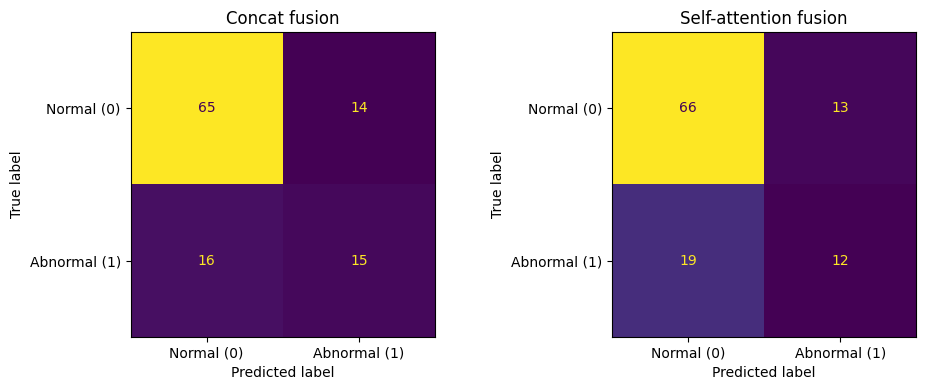

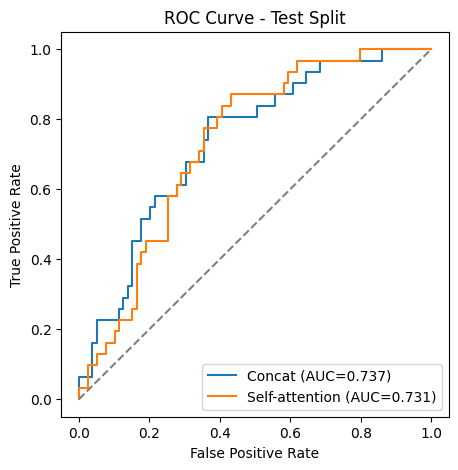

Saved: /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22/confusion_matrices.png and /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22/roc_curves.png


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cm_flat, title in zip(
    axes,
    [concat_test_metrics["confusion_matrix"], selfattn_test_metrics["confusion_matrix"]],
    ["Concat fusion", "Self-attention fusion"],
):
    cm = np.array(cm_flat)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal (0)", "Abnormal (1)"])
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
cm_png = os.path.join(RESULTS_DIR, "confusion_matrices.png")
plt.savefig(cm_png, dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
if len(set(concat_test_labels)) > 1:
    fpr_c, tpr_c, _ = roc_curve(concat_test_labels, concat_test_probs)
    ax.plot(fpr_c, tpr_c, label=f"Concat (AUC={concat_test_metrics['roc_auc']:.3f})")
if len(set(selfattn_test_labels)) > 1:
    fpr_s, tpr_s, _ = roc_curve(selfattn_test_labels, selfattn_test_probs)
    ax.plot(fpr_s, tpr_s, label=f"Self-attention (AUC={selfattn_test_metrics['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - Test Split"); ax.legend()
roc_png = os.path.join(RESULTS_DIR, "roc_curves.png")
plt.savefig(roc_png, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", cm_png, "and", roc_png)

## Step 12 — Final Comparison Table

        fusion  accuracy  precision  recall_sensitivity  specificity       f1  roc_auc     loss
        concat  0.727273   0.517241            0.483871     0.822785 0.500000 0.736627 0.527645
self_attention  0.709091   0.480000            0.387097     0.835443 0.428571 0.730911 0.919644


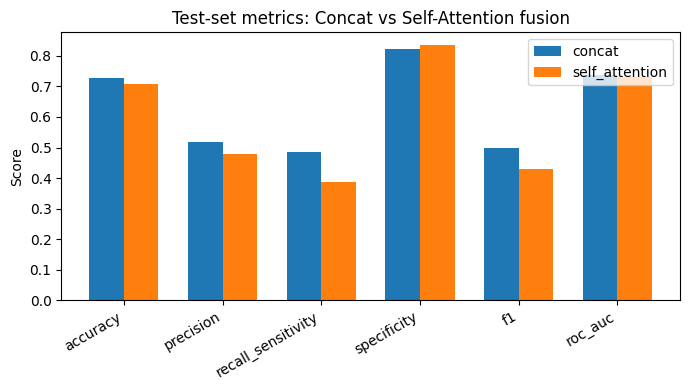


All outputs saved to the new results folder: /kaggle/working/AnaeCare_results/quick_fusion_test/2026-10-22
Used 512 train / 115 val / 110 test subjects, 20 epochs.


In [25]:
compare_df = pd.DataFrame([
    {"fusion": "concat", **{k: v for k, v in concat_test_metrics.items() if k != "confusion_matrix"}},
    {"fusion": "self_attention", **{k: v for k, v in selfattn_test_metrics.items() if k != "confusion_matrix"}},
])
cols = ["fusion", "accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc", "loss"]
print(compare_df[cols].to_string(index=False))

compare_csv = os.path.join(RESULTS_DIR, "quick_fusion_comparison.csv")
compare_df.to_csv(compare_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4))
metric_names = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc"]
x = np.arange(len(metric_names))
width = 0.35
ax.bar(x - width/2, compare_df.loc[compare_df["fusion"] == "concat", metric_names].values[0], width, label="concat")
ax.bar(x + width/2, compare_df.loc[compare_df["fusion"] == "self_attention", metric_names].values[0], width, label="self_attention")
ax.set_xticks(x); ax.set_xticklabels(metric_names, rotation=30, ha="right")
ax.set_ylabel("Score"); ax.set_title("Test-set metrics: Concat vs Self-Attention fusion")
ax.legend()
plt.tight_layout()
metrics_png = os.path.join(RESULTS_DIR, "quick_fusion_metrics_bar.png")
plt.savefig(metrics_png, dpi=150, bbox_inches="tight")
plt.show()

print("\nAll outputs saved to the new results folder:", RESULTS_DIR)
print(f"Used {len(train_df)} train / {len(val_df)} val / {len(test_df)} test subjects, {QUICK_EPOCHS} epochs.")

## Step 13 — Zip Everything & Get a Download Link

Bundles every file written to `RESULTS_DIR` this run — histories, test
metrics, confusion matrices, ROC curves, the comparison table/bar chart,
raw test probabilities/labels, and both trained models' weights
(`concat_model.pt`, `self_attention_model.pt`) — into a single `.zip` in
`/kaggle/working/`. Click the link below to download it directly, so the
results survive even after the session ends (Kaggle also keeps
`/kaggle/working/` as "Output" on the notebook version, but a manual
download right after the run is the safest bet).


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Read Excel file
df = pd.read_csv("/kaggle/input/datasets/shimu080/result-csv-1/concat_history-10-epoch.csv")

# Plot both losses
plt.figure(figsize=(8,5))

plt.plot(df["epoch"], df["train_loss"],
         marker="o", linewidth=2, label="Training Loss")

plt.plot(df["epoch"], df["loss"],
         marker="s", linewidth=2, label="Validation Loss")

plt.title("Training vs Validation Loss (concat)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(df["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

# Save graph
plt.savefig("concat_training_vs_validation_loss_10e.png", dpi=300, bbox_inches="tight")

# Display graph
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/shimu080/result-csv-1/concat_history-10-epoch.csv'

In [26]:
import shutil
from IPython.display import FileLink, display

zip_base = os.path.join(RESULTS_DIR_ROOT, f"anaecare_results_{_run_date}")
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("Files bundled into the zip:")
for root, _, files in os.walk(RESULTS_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, RESULTS_DIR)}  ({os.path.getsize(full) / 1024:.1f} KB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\nZip written to: {zip_path}  ({zip_size_mb:.1f} MB)")
print("Click below to download it (it's also visible under this notebook's Output tab):")
display(FileLink(os.path.relpath(zip_path, os.getcwd())))


Files bundled into the zip:
  concat_history.csv  (3.0 KB)
  concat_model.pt  (133147.5 KB)
  concat_test_metrics.json  (0.3 KB)
  concat_test_raw.npz  (1.4 KB)
  confusion_matrices.png  (33.2 KB)
  quick_fusion_comparison.csv  (0.3 KB)
  quick_fusion_metrics_bar.png  (47.4 KB)
  roc_curves.png  (47.0 KB)
  self_attention_history.csv  (3.0 KB)
  self_attention_model.pt  (134897.1 KB)
  self_attention_test_metrics.json  (0.3 KB)
  self_attention_test_raw.npz  (1.4 KB)

Zip written to: /kaggle/working/anaecare_results_2026-10-22.zip  (242.9 MB)
Click below to download it (it's also visible under this notebook's Output tab):


/kaggle/working/anaecare_results_2026-10-22.zip